# Step 1 — Dataset inspection

### Import libraries

In [1]:
import os
from pathlib import Path
import matplotlib.pyplot as plt
from PIL import Image

# Dataset path
DATA_DIR = Path(r"C:\Users\HP\Downloads\PRAICP-1000-IndiSignLang\Data")

# Check dataset path
print("Dataset exists:", DATA_DIR.exists())

# Display class folders
classes = sorted([folder.name for folder in DATA_DIR.iterdir()
                  if folder.is_dir()])

print("Total classes:", len(classes))
print("Classes:", classes)

Dataset exists: True
Total classes: 24
Classes: ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y']


### Count images in each class

In [2]:
image_extensions = {".jpg", ".jpeg", ".png", ".bmp"}

class_counts = {}

for class_name in classes:
    folder = DATA_DIR / class_name

    images = [f for f in folder.iterdir()
              if f.suffix.lower() in image_extensions]

    class_counts[class_name] = len(images)

print("Total images:", sum(class_counts.values()))

for class_name, count in class_counts.items():
    print(f"{class_name}: {count}")

Total images: 4972
A: 242
B: 259
C: 247
D: 147
E: 243
F: 226
G: 241
H: 116
I: 179
K: 245
L: 182
M: 235
N: 237
O: 229
P: 234
Q: 216
R: 211
S: 229
T: 216
U: 135
V: 122
W: 128
X: 202
Y: 251


### Visualize class distribution

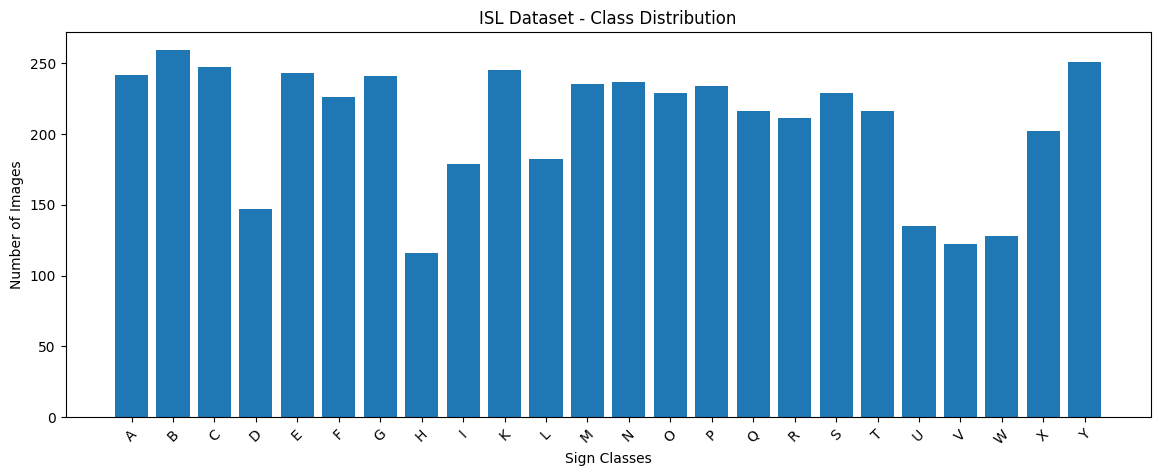

In [3]:
plt.figure(figsize=(14, 5))

plt.bar(class_counts.keys(), class_counts.values())

plt.title("ISL Dataset - Class Distribution")
plt.xlabel("Sign Classes")
plt.ylabel("Number of Images")
plt.xticks(rotation=45)

plt.show()

### Display sample images

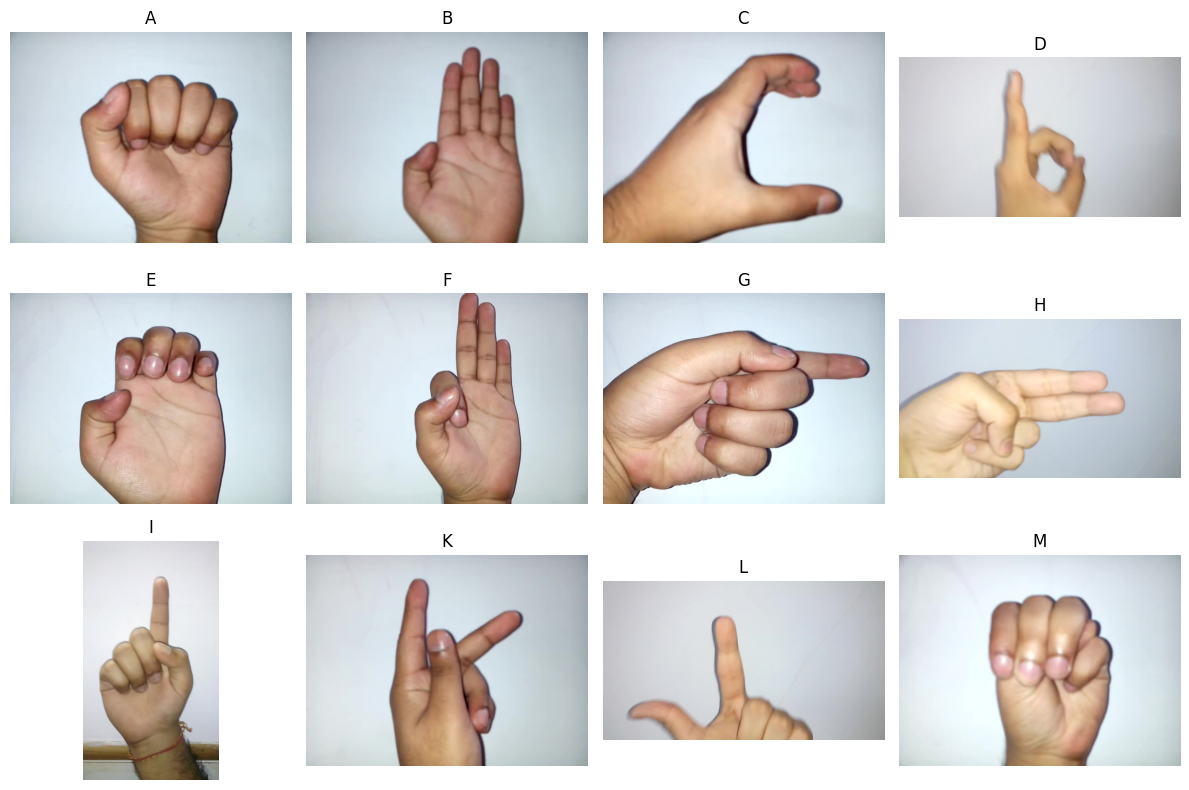

In [4]:
plt.figure(figsize=(12, 8))

for i, class_name in enumerate(classes[:12]):
    folder = DATA_DIR / class_name

    image_files = [f for f in folder.iterdir()
                   if f.suffix.lower() in image_extensions]

    if image_files:
        img = Image.open(image_files[0])

        plt.subplot(3, 4, i + 1)
        plt.imshow(img)
        plt.title(class_name)
        plt.axis("off")

plt.tight_layout()
plt.show()

# Step 2 — Image preprocessing

### 2.1 Import TensorFlow and check hardware

In [5]:
import tensorflow as tf

print("TensorFlow version:", tf.__version__)
print("Available GPU:", tf.config.list_physical_devices('GPU'))

TensorFlow version: 2.21.0
Available GPU: []


### 2.2 Load and split the dataset

In [6]:
IMG_SIZE = (160, 160)
BATCH_SIZE = 32
SEED = 42

train_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR,
    validation_split=0.2,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int"
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR,
    validation_split=0.2,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=False
)

class_names = train_ds.class_names

print("Classes:", class_names)
print("Training batches:", len(train_ds))
print("Validation batches:", len(val_ds))

Found 4972 files belonging to 24 classes.
Using 3978 files for training.
Found 4972 files belonging to 24 classes.
Using 994 files for validation.
Classes: ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y']
Training batches: 125
Validation batches: 32


### 2.3 Apply MobileNetV2 preprocessing

In [7]:
preprocess_input = tf.keras.applications.mobilenet_v2.preprocess_input

train_ds = train_ds.map(
    lambda x, y: (preprocess_input(x), y)
)

val_ds = val_ds.map(
    lambda x, y: (preprocess_input(x), y)
)

AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)

print("Preprocessing completed!")

Preprocessing completed!


### 2.4 Verify preprocessing

In [8]:
images, labels = next(iter(train_ds))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Minimum pixel value:", tf.reduce_min(images).numpy())
print("Maximum pixel value:", tf.reduce_max(images).numpy())

Image batch shape: (32, 160, 160, 3)
Label batch shape: (32,)
Minimum pixel value: -1.0
Maximum pixel value: 1.0


# Step 3 — Build the MobileNetV2 model

### 3.1 Understand the architecture

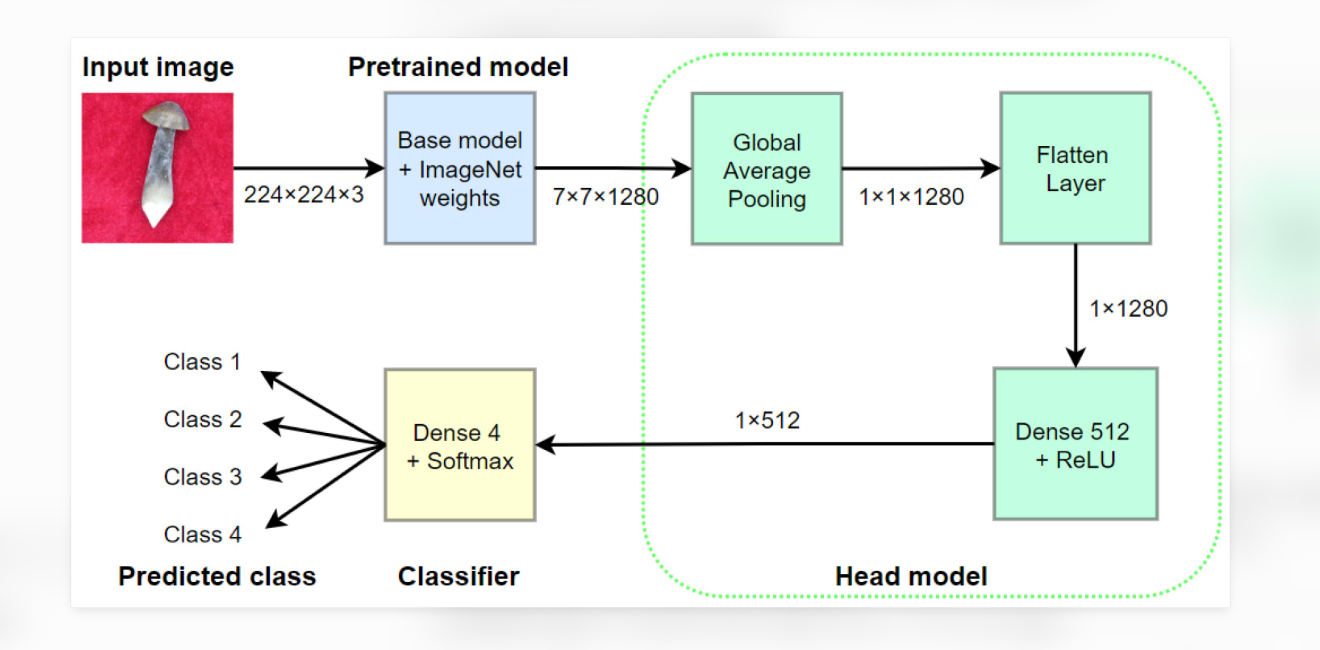

### 3.2 Load pretrained MobileNetV2

In [9]:
base_model = tf.keras.applications.MobileNetV2(
    input_shape=(160, 160, 3),
    include_top=False,
    weights="imagenet"
)

# Freeze pretrained layers
base_model.trainable = False

print("MobileNetV2 loaded successfully!")

MobileNetV2 loaded successfully!


### 3.3 Build our classification model

In [10]:
model = tf.keras.Sequential([
    tf.keras.Input(shape=(160, 160, 3)),

    base_model,

    tf.keras.layers.GlobalAveragePooling2D(),

    tf.keras.layers.Dropout(0.3),

    tf.keras.layers.Dense(24, activation="softmax")
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_160 (Functional)    │ (None, 5, 5, 1280)          │       2,257,984 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d             │ (None, 1280)                │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 1280)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 24)                  │          30,744 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 2,288,728 (8.73 MB)

 Trainable params: 30,744 (120.09 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

### 3.4 Compile the model

In [11]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

### 3.5 Train the model

In [12]:
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5,
    callbacks=[early_stopping]
)

Epoch 1/5
125/125 ━━━━━━━━━━━━━━━━━━━━ 92s 663ms/step - accuracy: 0.7552 - loss: 0.9986 - val_accuracy: 0.9608 - val_loss: 0.2579
Epoch 2/5
125/125 ━━━━━━━━━━━━━━━━━━━━ 75s 597ms/step - accuracy: 0.9744 - loss: 0.1584 - val_accuracy: 0.9940 - val_loss: 0.1039
Epoch 3/5
125/125 ━━━━━━━━━━━━━━━━━━━━ 39s 254ms/step - accuracy: 0.9915 - loss: 0.0800 - val_accuracy: 0.9990 - val_loss: 0.0505
Epoch 4/5
125/125 ━━━━━━━━━━━━━━━━━━━━ 43s 266ms/step - accuracy: 0.9947 - loss: 0.0513 - val_accuracy: 0.9990 - val_loss: 0.0374
Epoch 5/5
125/125 ━━━━━━━━━━━━━━━━━━━━ 34s 274ms/step - accuracy: 0.9972 - loss: 0.0351 - val_accuracy: 1.0000 - val_loss: 0.0285


### 3.6 Plot training performance

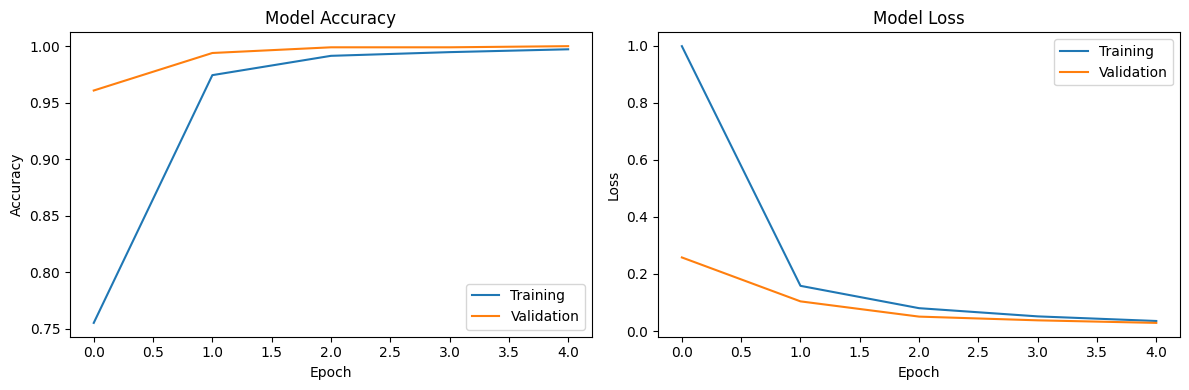

In [13]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training")
plt.plot(history.history["val_accuracy"], label="Validation")
plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training")
plt.plot(history.history["val_loss"], label="Validation")
plt.title("Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

# Step 4 — Model evaluation

### Generate predictions

In [14]:
import numpy as np

# Collect actual labels in the same, fixed order as validation predictions
y_true = np.concatenate([y.numpy() for x, y in val_ds])
y_prob = model.predict(val_ds)
y_pred = np.argmax(y_prob, axis=1)

print("Actual labels:", len(y_true))
print("Predicted labels:", len(y_pred))
print("Classes present in actual labels:", np.unique(y_true))
print("Classes present in predictions:", np.unique(y_pred))

assert len(y_true) == len(y_pred), "Actual and predicted sample counts do not match."


32/32 ━━━━━━━━━━━━━━━━━━━━ 10s 247ms/step
Actual labels: 994
Predicted labels: 994
Classes present in actual labels: [18 19 20 21 22 23]
Classes present in predictions: [18 19 20 21 22 23]


### Classification report

In [15]:
from sklearn.metrics import classification_report, accuracy_score

# Explicitly include all 24 classes, even if a class has no samples/predictions
all_labels = np.arange(len(class_names))

print("Validation Accuracy:", accuracy_score(y_true, y_pred))

print(classification_report(
    y_true,
    y_pred,
    labels=all_labels,
    target_names=class_names,
    zero_division=0
))


Validation Accuracy: 1.0
              precision    recall  f1-score   support

           A       0.00      0.00      0.00         0
           B       0.00      0.00      0.00         0
           C       0.00      0.00      0.00         0
           D       0.00      0.00      0.00         0
           E       0.00      0.00      0.00         0
           F       0.00      0.00      0.00         0
           G       0.00      0.00      0.00         0
           H       0.00      0.00      0.00         0
           I       0.00      0.00      0.00         0
           K       0.00      0.00      0.00         0
           L       0.00      0.00      0.00         0
           M       0.00      0.00      0.00         0
           N       0.00      0.00      0.00         0
           O       0.00      0.00      0.00         0
           P       0.00      0.00      0.00         0
           Q       0.00      0.00      0.00         0
           R       0.00      0.00      0.00         0
  

### Confusion matrix

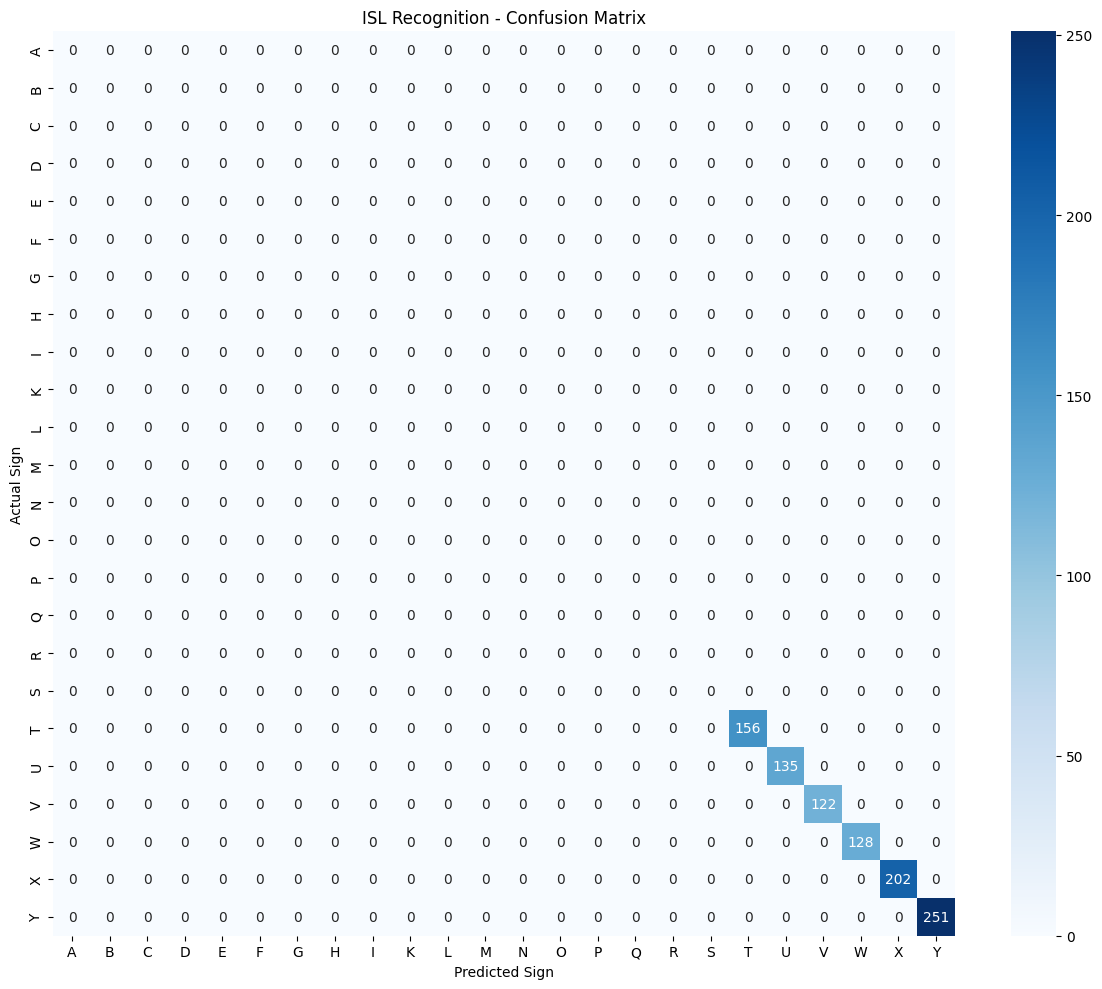

In [16]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

cm = confusion_matrix(y_true, y_pred, labels=np.arange(len(class_names)))

plt.figure(figsize=(12, 10))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)
plt.title("ISL Recognition - Confusion Matrix")
plt.xlabel("Predicted Sign")
plt.ylabel("Actual Sign")
plt.tight_layout()
plt.show()


### Test individual predictions

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step


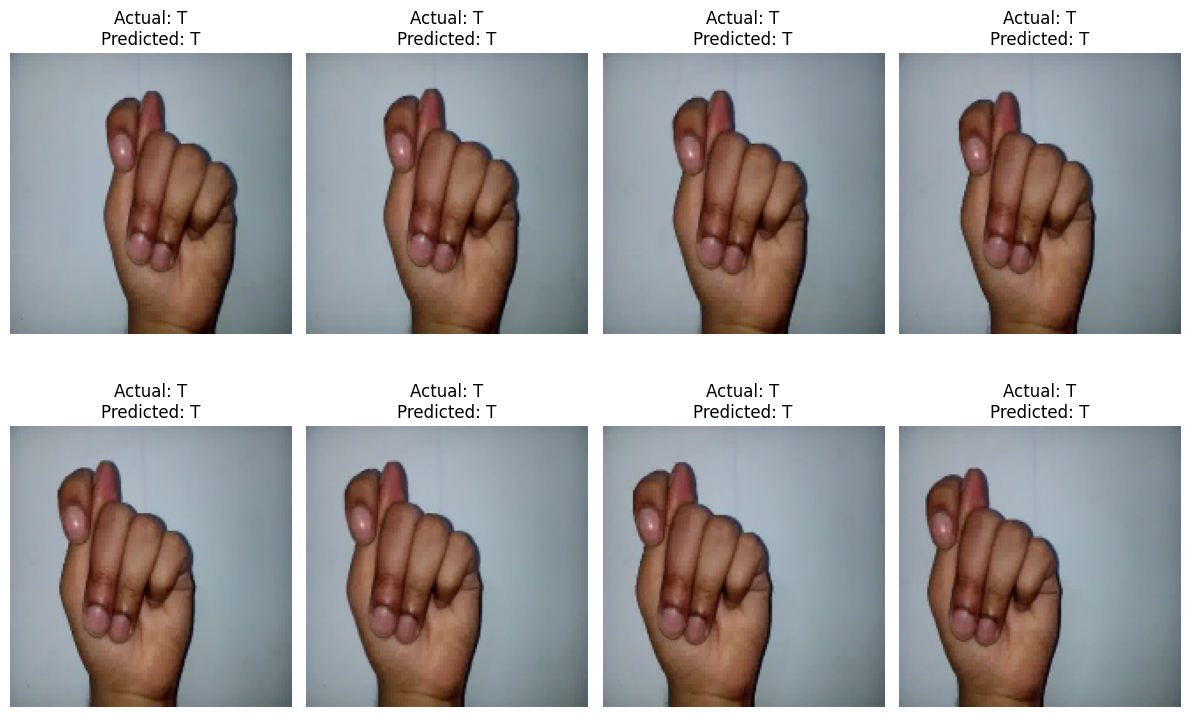

In [17]:
images, labels = next(iter(val_ds))

predictions = model.predict(images)

plt.figure(figsize=(12, 8))

for i in range(8):
    actual = class_names[labels[i].numpy()]
    predicted = class_names[np.argmax(predictions[i])]

    plt.subplot(2, 4, i + 1)
    plt.imshow((images[i].numpy() + 1) / 2)

    plt.title(f"Actual: {actual}\nPredicted: {predicted}")
    plt.axis("off")

plt.tight_layout()
plt.show()

### Random sample predictions

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step


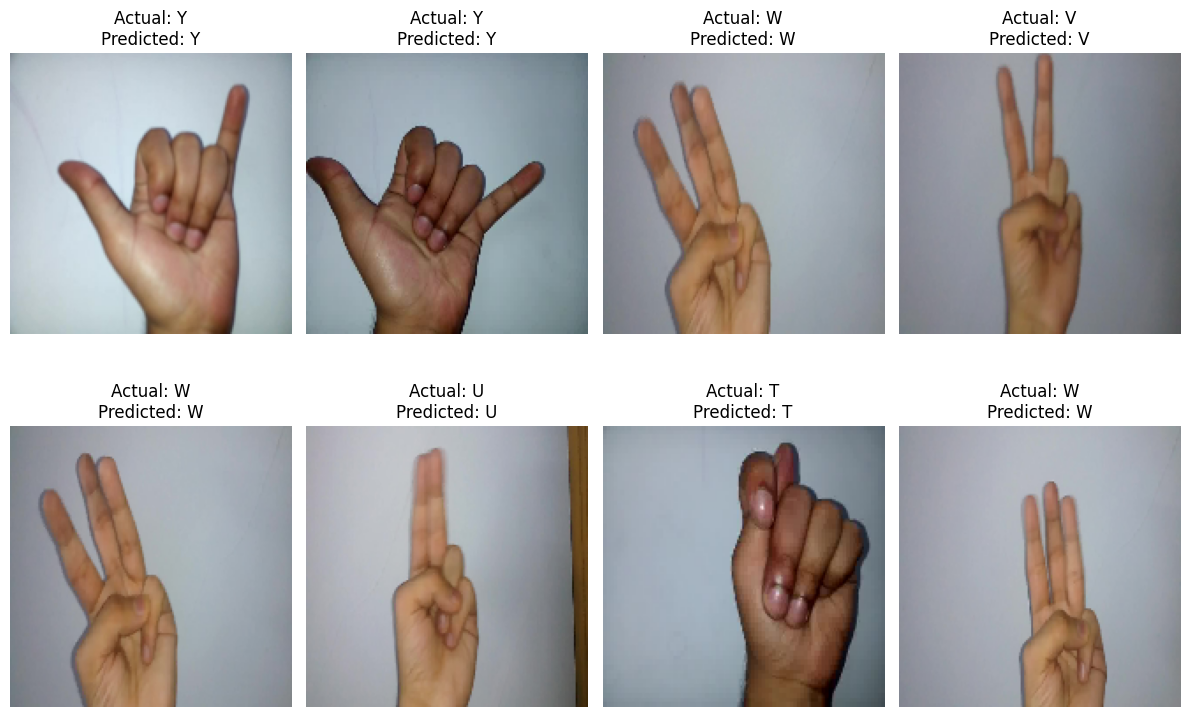

In [18]:
# Randomly select 8 images from the entire validation dataset
sample_images, sample_labels = next(
    iter(
        val_ds.unbatch()
        .shuffle(buffer_size=994, seed=42)
        .batch(8)
        .take(1)
    )
)

# Predict signs
predictions = model.predict(sample_images)

# Visualize predictions
plt.figure(figsize=(12, 8))

for i in range(8):

    actual = class_names[sample_labels[i].numpy()]
    predicted = class_names[np.argmax(predictions[i])]

    plt.subplot(2, 4, i + 1)

    plt.imshow((sample_images[i].numpy() + 1) / 2)

    plt.title(f"Actual: {actual}\nPredicted: {predicted}")
    plt.axis("off")

plt.tight_layout()
plt.show()

Indian Sign Language (ISL) Recognition
1. Problem Statement
The goal of this project is to build an image-classification model that
recognizes Indian Sign Language alphabet hand signs. The system takes an
image of a hand sign as input and predicts the corresponding alphabet.
2. Dataset
- Dataset: PRAICP-1000-IndiSignLang
- Classes: 24 alphabet classes (A--I and K--Y; J and Z are not
  included)
- Total images: 4,972
- Training images: 3,978 (80%)
- Validation images: 994 (20%)
3. Approach
1. Inspected the class folders, image counts, and sample images.
2. Resized images to 160 × 160 pixels and prepared batches of 32
   images.
3. Applied MobileNetV2 preprocessing to scale pixel values to the range
   \(-1, 1\).
4. Used MobileNetV2 with ImageNet pretrained weights as a frozen
   feature extractor.
5. Added Global Average Pooling, Dropout, and a 24-unit Softmax output
   layer.
6. Trained the classification head for up to five epochs and evaluated
   predictions using a classification report and confusion matrix.
4. Model Training
The initial training run reported the following results after five
epochs:
- Training accuracy: 99.75%
- Validation accuracy: 99.80%
- Training loss: 0.0327
- Validation loss: 0.0233
These are the metrics from the training run. The final corrected
evaluation metrics should be taken from the corrected classification
report, as the validation prediction and label ordering issue was fixed
separately.
5. Problems Faced and Solutions
  Problem                             Solution
  The dataset contained images        Used TensorFlow's
organized in class-specific         image_dataset_from_directory() to
folders.                            load images and assign labels
automatically.

  Images needed a consistent input    Resized images to 160 × 160 and
size and pixel range.               applied MobileNetV2 preprocessing.

  GPU was not available in the        Used a lightweight
environment.                        transfer-learning setup with the
MobileNetV2 base layers frozen.

  The first evaluation report showed  Recreated the validation dataset
unexpectedly low accuracy because   with shuffle=False and generated
labels and predictions could be     labels and predictions in the same
misaligned between separate         fixed order.
iterations of a shuffled validation
dataset.                            
The first prediction visualization  Randomly sampled images from the
displayed images from only one      validation dataset for
class.                              visualization, without changing the
evaluation dataset.
6. Conclusion
This project demonstrates how transfer learning with MobileNetV2 can be
used to classify Indian Sign Language alphabet images. The model was
trained on 24 classes using a relatively small image dataset, and
individual image predictions were successfully demonstrated.

The project is an image-based alphabet classifier, not a complete
real-time sign-language translation system. It does not yet interpret
continuous gestures, facial expressions, or sentence-level sign
language. Further testing on unseen images and different users,
backgrounds, lighting conditions, and hand orientations is needed before
real-world deployment.
7. Future Improvements
- Test the model on an independent test set and images from different
  users.
- Check for duplicate or near-duplicate images across dataset splits.
- Improve robustness using appropriate data augmentation.
- Build a webcam-based application for live sign recognition.
- Extend the system to recognize dynamic signs and sequences.